# separar los datos que son calculados analiticamente del dataset (si se quiere hacer hipotesis sobre ellos)
- Aunque aprox son 200 muestras, no es lo suficientemente relevante el numero para sacar conclusiones de ellos



## Posibles hipotesis

Univariada:
- Axle ratio– qsy algo del promedio del ratio. o si el promedio tiende para bajo o alto (no se que es alto o bajo) ya pre condiciona a que la mayoría de los autos van a gastar mas  Axle Ratio más alto - >Menor MPG (Mayor consumo): El motor va girando a más revoluciones a la misma velocidad, quemando más combustible. – alta 4.10 o mas 

- 

Bivariada
- los autos electricos consumen menos que los autos a combustion ( MPG - Test fuel type description)-- preguntar porque hay mas de combustion que de electricos y por la diferencia entre los MPGs de los dos, habra que estandarizar??, (hay algunos nan en el de RND_ADJ_FE y por lo que pude ver son en autos de combustion con un tipo de test CD)
- En autos a combustión, la cantidad de caballos de fuerza tiene correlacion con lo que gasta un auto, a mayor potencia menos MPG (la regla es a mayor MPG mas recorre por galon)

Multivariada:
- Lo de los gases emitidos por marca o por familia de motores

In [30]:

import pandas as pd
import numpy as np

df = pd.read_excel('25-testcar-2026-01-21.xlsx')

In [31]:
df.value_counts("Test Fuel Type Description")

Test Fuel Type Description
Tier 2 Cert Gasoline                             3236
Electricity                                       654
Cold CO Regular (Tier 2)                          160
Federal Cert Diesel 7-15 PPM Sulfur               150
Cold CO Premium (Tier 2)                           57
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        12
Hydrogen 5                                         10
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       3
Cold CO E10 Regular Gasoline (Tier 3)               2
CARB LEV3 E10 Premium Gasoline                      2
CARB LEV3 E10 Regular Gasoline                      1
Name: count, dtype: int64

In [32]:
df.value_counts("Vehicle Manufacturer Name")

Vehicle Manufacturer Name
GM                      697
BMW                     597
Toyota                  523
Hyundai                 317
Volkswagen Group of     280
FOMOCO                  255
Mercedes-Benz           205
Nissan                  191
Kia                     167
Porsche                 152
Honda                   144
FCA US LLC              131
MAZDA                    82
Jaguar Land Rover L      79
Rivian Automotive L      77
Subaru                   68
Volvo                    67
Ferrari                  50
Tesla                    43
Maserati                 31
Mitsubishi Motors Co     25
Wuhan Lotus Cars Co      24
Lucid USA, Inc           20
Vinfast Trading and      20
Rolls-Royce              10
aston martin              8
Lotus                     8
Ineos Automotive Li       6
Karma Automotive          4
Bugatti Rimac LLC         2
CZV Inc                   2
Pagani S.p.A.             2
Name: count, dtype: int64

HIPOTESIS DE AXLE RADIO: Axle ratio– podemos analizar el promedio del ratio. o si el promedio tiende para bajo o alto, ya pre condiciona a que la mayoría de los autos van a gastar mas  
Axle Ratio más alto - >Menor MPG (Mayor consumo): El motor va girando a más revoluciones a la misma velocidad, quemando más combustible. – alta 3.73, 4.10 o +

¿Los vehículos testeados por la EPA en 2025 tienen, en promedio, un axle ratio inferior al de referencia de 3,0?

H0: μ(Axle Ratio) >= 3,7
H1: μ(Axle Ratio) < 3,7


es una variable cuantitativa continua, por lo que primero vamos a hacer un grafico de boxplot, histograma, qq-plot 


Pregunta:
- lo hacemos solo de autos de combulsion?? ya que capaz que el combustible electrico no se cuenta, porque no hay combustible electrico
- como el axle ratio en una carateristica del auto, y hay en algunos casos varios test por auto, me quedo solo con una muestra de cada auto, para que sean independientes y para que no se vean influidos los datos por repeticiones????

lo hice para vehiculos de combustion

In [33]:
df["Axle Ratio"].isna().sum()

np.int64(0)

podemos ver que no tiene nulos literales, ver nulos no Nan

In [34]:
df["Axle Ratio"].value_counts()

Axle Ratio
3.23    340
1.00    266
2.81    129
9.99    118
3.42     98
       ... 
4.30      2
3.04      2
9.20      2
2.58      2
2.55      2
Name: count, Length: 162, dtype: int64

Tampoco se ve que existen nulos de otros tipos

Nos quedamos solo con los autos de combustion

In [35]:
df["Test Fuel Type Description"].value_counts()

Test Fuel Type Description
Tier 2 Cert Gasoline                             3236
Electricity                                       654
Cold CO Regular (Tier 2)                          160
Federal Cert Diesel 7-15 PPM Sulfur               150
Cold CO Premium (Tier 2)                           57
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        12
Hydrogen 5                                         10
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       3
Cold CO E10 Regular Gasoline (Tier 3)               2
CARB LEV3 E10 Premium Gasoline                      2
CARB LEV3 E10 Regular Gasoline                      1
Name: count, dtype: int64

Los separaría en dos grupos según tenga sentido físico el axle ratio:

Grupo	Categorías	Filas
Combustión interna	Tier 2 Cert Gasoline, Cold CO Regular, Cold CO Premium, Cold CO E10, Tier 3 E10, CARB LEV3 E10 Premium, Federal Cert Diesel, E85	1.098
Sin motor de combustión	Electricity, Hydrogen 5	349
Los “Cold CO” son ensayos de monóxido de carbono a baja temperatura. Es el mismo tipo de auto de gasolina con otro procedimiento, así que van con combustión.
Diésel (17) y E85 (2) son pocos como para analizarlos aparte. Los dejaría dentro de combustión interna, porque tienen motor y transmisión convencionales, y lo aclararía en el informe.
Hydrogen son vehículos de celda de combustible, que mueven un motor eléctrico, así que el “axle ratio” es una reducción fija y no comparable con el de un auto de combustión.

Esta clasificación es un criterio independiente del valor del axle ratio, y eso es lo que la hace defendible.

In [36]:
col_fuel = "Test Fuel Type Description"

print(df[col_fuel].isna().sum(), "filas sin tipo de combustible")

# 1. Filtrar combustión interna (excluye eléctricos e hidrógeno)
sinCombustion = df[col_fuel].str.contains("Electricity|Hydrogen")
df_procesado = df[~sinCombustion] #invierte la condicion, deja los que son de combustion


0 filas sin tipo de combustible


ahora resolvemos lo de los autos duplicados -- cambiarlo por lo de vehicule ID

In [37]:
n_valores = df_procesado.groupby("Test Vehicle ID")["Axle Ratio"].nunique()

print("IDs con más de un Axle Ratio:", (n_valores > 1).sum())
print("Total de IDs:", n_valores.shape[0])

IDs con más de un Axle Ratio: 0
Total de IDs: 740


In [38]:
# quedar primera fila de cada columna
df_procesado = df_procesado.drop_duplicates(subset=["Test Vehicle ID"], keep="first").reset_index(drop=True)
df_procesado["Axle Ratio"].describe()

count    740.000000
mean       3.634514
std        0.744179
min        1.560000
25%        3.230000
50%        3.470000
75%        3.800000
max        8.500000
Name: Axle Ratio, dtype: float64

In [39]:
df_procesado["Axle Ratio"].value_counts()

Axle Ratio
3.58    25
3.23    25
3.73    23
3.27    22
3.33    20
        ..
3.14     1
2.58     1
2.55     1
2.62     1
4.47     1
Name: count, Length: 136, dtype: int64

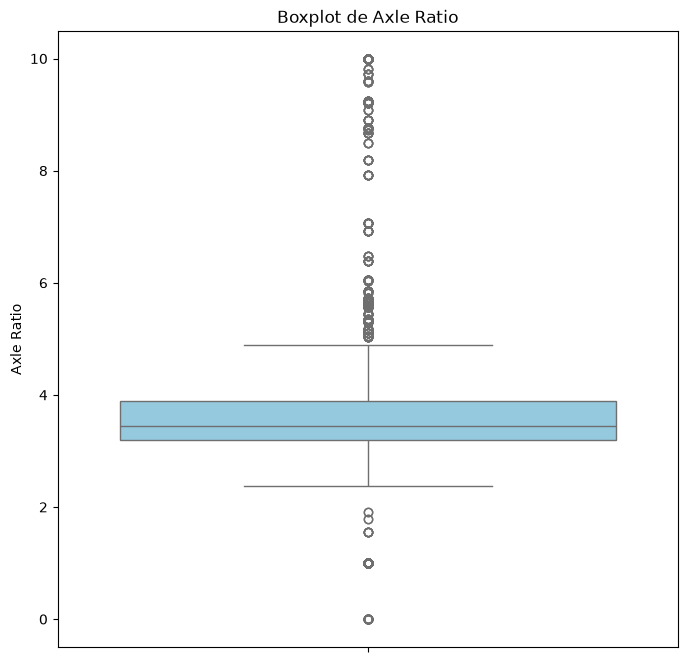

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
sns.boxplot(y=df["Axle Ratio"], color="skyblue")
plt.title("Boxplot de Axle Ratio")
plt.ylabel("Axle Ratio")
plt.show()

Se puede ver que hay muchos valores outliers, hay muchos autos la mayoria con axle ratio muy grandes 

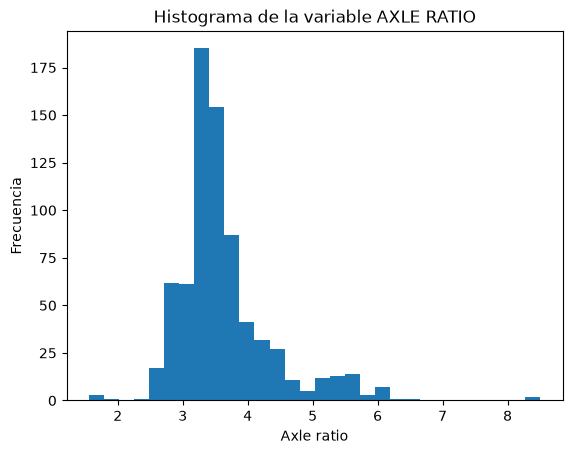

In [41]:
plt.hist(df_procesado["Axle Ratio"], bins=30)

# Agregar etiquetas a los ejes
plt.xlabel("Axle ratio")
plt.ylabel("Frecuencia")

# Agregar un título al gráfico
plt.title("Histograma de la variable AXLE RATIO")

# Mostrar el gráfico
plt.show()

la hipotesis era que la media de los axle ratio, en los autos de combustion, es menor a 3.43 (que esta en el documento que es alta, preguntar de donde salio eso).

para eso hay que hacer un test de prueba t, primero hay que probar el supuesto de normalidad, para probarla haremos un test de shapiro-wilks

count    740.000000
mean       3.634514
std        0.744179
min        1.560000
25%        3.230000
50%        3.470000
75%        3.800000
max        8.500000
Name: Axle Ratio, dtype: float64
Asimetría: 1.88 | Curtosis: 6.29
0 con <= 1 | 2 con >= 7


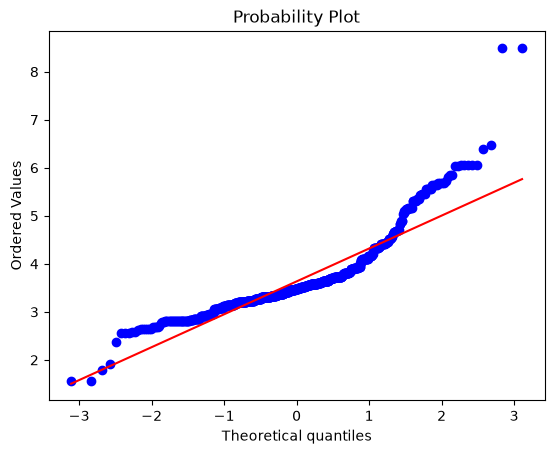

In [42]:
from scipy import stats
import matplotlib.pyplot as plt

x = df_procesado["Axle Ratio"]

print(x.describe())
print("Asimetría:", round(stats.skew(x), 2), "| Curtosis:", round(stats.kurtosis(x), 2))
print((x <= 1).sum(), "con <= 1 |", (x >= 7).sum(), "con >= 7")

stats.probplot(x, dist="norm", plot=plt)   # gráfico Q-Q
plt.show()

In [43]:
from scipy.stats import shapiro

# Separamos los datos en dos grupos, desarrollados y en vías de desarrollo
Axle_ratio = df_procesado["Axle Ratio"]

# Test de Shapiro-Wilk para países desarrollados
stat, p = shapiro(Axle_ratio)
print(f"Test de Shapiro-Wilk para axle ratio: Estadístico={stat:.3f}, p-valor={p:.3f}")


Test de Shapiro-Wilk para axle ratio: Estadístico=0.845, p-valor=0.000


Podemos observar tanto por el qq plot como por el test de shapiro (p menor a 0.05) que la variable axl ratio no ditribulle normal, por lo cual no se puede usar el test t.

ahora probamos homocedasticidad: para eso necesito dos variables, no se que hacer si existe otro test para cuando solo hay una variable que no es normal, o en este caso solo con el promedio alcanza??????

suma de rangos de wincoxon??? o como el n es muy grande igual puedo hacer el de test t

In [44]:
print("desvío:", x.std())
print("(media - mediana) / desvío:", (x.mean() - x.median()) / x.std())

desvío: 0.7441791482489857
(media - mediana) / desvío: 0.221067082974046


In [45]:
from scipy.stats import wilcoxon

datos = df["Axle Ratio"].dropna()

diferencias = datos - 3.73

estadistico, p_valor = wilcoxon(
    diferencias,
    alternative="greater",
    method="auto"
)

print("Mediana muestral:", datos.median())
print("Estadístico:", estadistico)
print("P-valor:", p_valor)

if p_valor < 0.05:
    print("Se rechaza H0")
    print("Hay evidencia de que la mediana supera 3.73")
else:
    print("No se rechaza H0")
    print("No hay evidencia suficiente para afirmar que la mediana supera 3.73")

Mediana muestral: 3.45
Estadístico: 3218221.5
P-valor: 1.0
No se rechaza H0
No hay evidencia suficiente para afirmar que la mediana supera 3.73


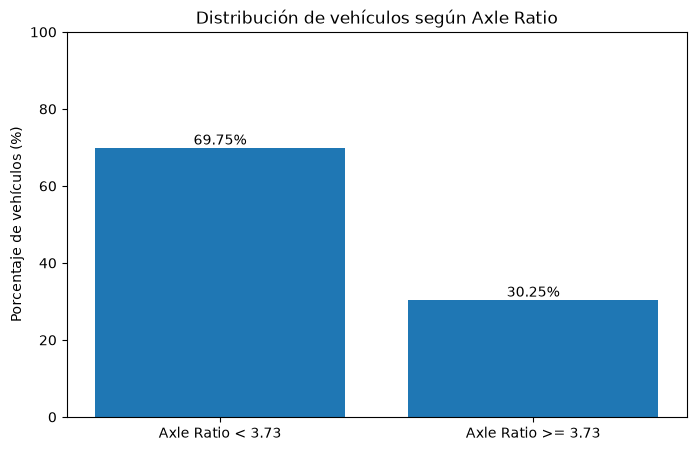

In [46]:
import matplotlib.pyplot as plt

datos = df["Axle Ratio"].dropna()

menor = (datos < 3.73).sum()
mayor_igual = (datos >= 3.73).sum()

porcentajes = [
    menor / len(datos) * 100,
    mayor_igual / len(datos) * 100
]

categorias = [
    "Axle Ratio < 3.73",
    "Axle Ratio >= 3.73"
]

plt.figure(figsize=(8, 5))

barras = plt.bar(categorias, porcentajes)

plt.title("Distribución de vehículos según Axle Ratio")
plt.ylabel("Porcentaje de vehículos (%)")
plt.ylim(0, 100)

for barra, porcentaje in zip(barras, porcentajes):
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 1,
        f"{porcentaje:.2f}%",
        ha="center"
    )

plt.show()

In [47]:
#test de wilcoxon--- AHORA ME DICEN QUE NO SE PUEDE PORQUE NO ES SIMETRICAAAAAAAAAAAAAAAAAAAAAAAAAAA

### Hipotesis multivariada dada: 

Entre vehículos a combustion, las características técnicas del vehículo (peso, potencia, cilindrada, número de cilindros, transmisión y sistema de
tracción) se encuentran asociadas conjuntamente con su eficiencia de combustible urbana..

Tengo que quedarme con los autos de combustion, despues los que se probaron en condiciones urbanas y de ahi ver como las caracteristicas tecnicas se relacionan con la eficiencia del combustible(MPG)????

primero nos quedamos solo con los autos a combustion, como en la otra

In [48]:
col_fuel = "Test Fuel Type Description"

print(df[col_fuel].isna().sum(), "filas sin tipo de combustible")

# 1. Filtrar combustión interna (excluye eléctricos e hidrógeno)
sinCombustion = df[col_fuel].str.contains("Electricity|Hydrogen")
df_procesado = df[~sinCombustion] #invierte la condicion, deja los que son de combustion

0 filas sin tipo de combustible


Ahora solo con los test urbanos, para eso vemos la variable Test Category
Valor	Ciclo	
FTP	Federal Test Procedure, el ciclo urbano estándar	
HWY	Ruta	
US06	Conducción agresiva y a alta velocidad	
SC03	Con aire acondicionado, en calor	
CD	Charge-depleting, modo de híbridos enchufables	

In [49]:
df_procesado["Test Category"].value_counts()

Test Category
FTP     1547
HWY     1313
US06     393
SC03     240
CD       130
Name: count, dtype: int64

me quedo solo con las de FTP

In [50]:
df_procesado = df_procesado[df_procesado["Test Category"] == "FTP"]

print(pd.crosstab(df_procesado["Test Procedure Description"], df_procesado["Test Category"]))

Test Category                               FTP
Test Procedure Description                     
CVS 75 and later (w/o can. load)             51
California fuel 2-day exhaust (w/can load)   11
Cold CO                                     221
Federal fuel 2-day exhaust (w/can load)     923
Federal fuel 3-day exhaust                  341


In [51]:
df_procesado["Test Fuel Type Description"].value_counts()

Test Fuel Type Description
Tier 2 Cert Gasoline                             1270
Cold CO Regular (Tier 2)                          160
Cold CO Premium (Tier 2)                           57
Federal Cert Diesel 7-15 PPM Sulfur                51
E85 (85% Ethanol 15% EPA Unleaded Gasoline)         5
Cold CO E10 Regular Gasoline (Tier 3)               2
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       1
CARB LEV3 E10 Premium Gasoline                      1
Name: count, dtype: int64

Dejo solo las que tienen el mismo valor en "Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"

In [52]:
CLAVE = ["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"]
VARIABLES = [
    "Equivalent Test Weight (lbs.)",
    "Rated Horsepower",
    "Test Veh Displacement (L)",
    "# of Cylinders and Rotors",
    "Tested Transmission Type", 
    "Drive System Description"
]

variacion = df_procesado.groupby(CLAVE)[VARIABLES].nunique()

configuraciones_con_diferencias = variacion[
    (variacion > 1).any(axis=1)
]

print("Configuraciones con diferencias en características técnicas:",
      len(configuraciones_con_diferencias))

display(configuraciones_con_diferencias)

Configuraciones con diferencias en características técnicas: 0


,,,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type,Drive System Description
Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,,,,,,


trabajar con una observación por configuración, calculando el promedio de RND_ADJ_FE cuando hay mediciones repetidas.

Así evitás que una misma configuración tenga más peso en la regresión simplemente por aparecer más veces.

In [53]:
df_procesado = (
    df_procesado
    .groupby(CLAVE, as_index=False)
    .agg({
        "RND_ADJ_FE": "mean",
        "Equivalent Test Weight (lbs.)": "first",
        "Rated Horsepower": "first",
        "Test Veh Displacement (L)": "first",
        "# of Cylinders and Rotors": "first",
        "Tested Transmission Type": "first",
        "Drive System Description": "first"
    })
)

df_procesado.count()

Veh Mfr Code                     1087
Test Vehicle ID                  1087
Test Veh Configuration #         1087
RND_ADJ_FE                       1087
Equivalent Test Weight (lbs.)    1087
Rated Horsepower                 1087
Test Veh Displacement (L)        1087
# of Cylinders and Rotors        1084
Tested Transmission Type         1087
Drive System Description         1087
dtype: int64

In [54]:
df_procesado["RND_ADJ_FE"].isna().sum()

df_procesado["RND_ADJ_FE"].value_counts()

RND_ADJ_FE
34.10    10
23.70     9
29.00     8
23.50     8
21.50     8
         ..
25.20     1
22.25     1
32.45     1
37.80     1
22.35     1
Name: count, Length: 464, dtype: int64

parecen no haber nulos, implicitos o no

In [55]:
df_procesado["RND_ADJ_FE"].describe()

count     1087.000000
mean        58.403735
std        527.877806
min          9.500000
25%         22.300000
50%         27.200000
75%         33.750000
max      10000.000000
Name: RND_ADJ_FE, dtype: float64

rarisimo ese maximo

In [56]:
mpg = "RND_ADJ_FE"

malos = df_procesado[df_procesado[mpg] >= 1000]
print(len(malos), "filas con MPG >= 1000")
print(malos[["Represented Test Veh Make", "Represented Test Veh Model",
             "Test Procedure Description", "Analytically Derived FE?", mpg]])

4 filas con MPG >= 1000


KeyError: "['Represented Test Veh Make', 'Represented Test Veh Model', 'Test Procedure Description', 'Analytically Derived FE?'] not in index"

Se pasan a Nan ya que son numeros "imposibles" para el MSG, no son logicos se los cuentan como errores o nulos 

In [ ]:
mpg = "RND_ADJ_FE"

df_procesado.loc[df_procesado[mpg] >= 1000, mpg] = np.nan

print(df_procesado[mpg].isna().sum(), "MPG convertidos a faltante")  # debería dar 6
print(df_procesado[mpg].describe())

6 MPG convertidos a faltante
count    1541.000000
mean       28.958274
std        10.662479
min         9.200000
25%        21.800000
50%        27.100000
75%        34.000000
max        82.800000
Name: RND_ADJ_FE, dtype: float64


El maximo sigue siendo bastante alto, habria que eliminar a los hibridos que suelen tener MPG mas alto??

In [ ]:
print(df_procesado["Equivalent Test Weight (lbs.)"].value_counts())

Equivalent Test Weight (lbs.)
4250    130
4750    121
4000    108
4500     98
5500     90
5000     89
6000     77
3875     60
3500     59
5250     51
3375     45
3750     44
6500     42
3625     37
3250     19
3000      6
3125      5
7000      2
2875      2
2750      2
Name: count, dtype: int64


In [ ]:
num = ["Equivalent Test Weight (lbs.)", "Rated Horsepower"]   
for c in num:
    print(c)
    print("nulos:",df_procesado[c].isna().sum())
    print(df_procesado[c].describe())
    print(df_procesado[c].value_counts().head(5), "\n")

Equivalent Test Weight (lbs.)
nulos: 0
count    1547.000000
mean     4589.528119
std       854.881106
min      2750.000000
25%      4000.000000
50%      4500.000000
75%      5250.000000
max      7000.000000
Name: Equivalent Test Weight (lbs.), dtype: float64
Equivalent Test Weight (lbs.)
4250    190
4000    153
4750    152
5500    150
4500    141
Name: count, dtype: int64 

Rated Horsepower
nulos: 0
count    1547.000000
mean      313.254040
std       144.658095
min         1.000000
25%       197.500000
50%       287.000000
75%       375.000000
max      1500.000000
Name: Rated Horsepower, dtype: float64
Rated Horsepower
255    69
375    68
305    56
400    48
355    47
Name: count, dtype: int64 



raro el minimo en potencia -- eliminamos los que tienen 1 porque lo consideramos como una forma de poner nulo, ningun auto funcional tiene 1 caballo de fuerza

In [ ]:
# Ahora sí funcionará tu filtro 
hp = "Rated Horsepower"
df_procesado = df_procesado[df_procesado[hp] != 1]

df_procesado[hp].describe()


count    1545.000000
mean      313.658252
std       144.314270
min        97.000000
25%       200.000000
50%       287.000000
75%       375.000000
max      1500.000000
Name: Rated Horsepower, dtype: float64

In [61]:
df_procesado["Rated Horsepower"].value_counts()

Rated Horsepower
375     45
255     40
400     33
201     22
300     22
        ..
259      1
1500     1
771      1
456      1
563      1
Name: count, Length: 177, dtype: int64

In [ ]:
df_procesado[df_procesado["Rated Horsepower"] == 1500]

es comun que tengan potencia de 1500?? como la media es de 313 mepa que no 

In [ ]:
num = ["Test Veh Displacement (L)", "# of Cylinders and Rotors"]   
for c in num:
    print("nulos:",df_procesado[c].isna().sum())
    print(df_procesado[c].describe())
    print(df_procesado[c].value_counts().head(5), "\n")

nulos: 0
count    1545.000000
mean        2.854678
std         1.106103
min         1.200000
25%         2.000000
50%         2.500000
75%         3.445000
max         7.993000
Name: Test Veh Displacement (L), dtype: float64
Test Veh Displacement (L)
2.000    304
3.000    215
2.500    137
2.487     81
3.500     68
Name: count, dtype: int64 

nulos: 3
count    1542.000000
mean        5.195201
std         1.621610
min         3.000000
25%         4.000000
50%         4.000000
75%         6.000000
max        16.000000
Name: # of Cylinders and Rotors, dtype: float64
# of Cylinders and Rotors
4.0     830
6.0     447
8.0     216
3.0      33
12.0     13
Name: count, dtype: int64 



el numero de cilindros tiene 3 nulos, me fijo de que son

In [ ]:
ncil = "# of Cylinders and Rotors"
print(df_procesado[df_procesado[ncil].isna()][
    ["Represented Test Veh Make", "Represented Test Veh Model",
     "Test Veh Displacement (L)"] + CLAVE])

     Represented Test Veh Make Represented Test Veh Model  \
8                          BMW                 230i Coupe   
2522                     MAZDA                       CX-5   
2524                     MAZDA                       CX-5   

      Test Veh Displacement (L) Veh Mfr Code Test Vehicle ID  \
8                           2.0          BMX         8C99708   
2522                        2.5          TKX    8EBPYUG1-026   
2524                        2.5          TKX    8EBPYUG1-026   

      Test Veh Configuration #  
8                            0  
2522                         0  
2524                         1  


al ser solo tres decidi eliminar esas filas

In [ ]:
df_procesado = df_procesado.dropna(subset=[ncil])

print("nulos", df_procesado[ncil].isna().sum())
df_procesado[ncil].describe()

nulos 0


count    1542.000000
mean        5.195201
std         1.621610
min         3.000000
25%         4.000000
50%         4.000000
75%         6.000000
max        16.000000
Name: # of Cylinders and Rotors, dtype: float64

In [ ]:
num = ["Tested Transmission Type", "Drive System Description"]   
for c in num:
    print(c)
    print("Nulos:", df_procesado[c].isna().sum()) 
    print(df_procesado[c].describe())
    print(df_procesado[c].value_counts().head(5), "\n")

Tested Transmission Type
Nulos: 0
count               1542
unique                 7
top       Semi-Automatic
freq                 543
Name: Tested Transmission Type, dtype: object
Tested Transmission Type
Semi-Automatic                                                       543
Automatic                                                            437
Automated Manual- Selectable (e.g. Automated Manual with paddles)    206
Continuously Variable                                                201
Selectable Continuously Variable (e.g. CVT with paddles)              76
Name: count, dtype: int64 

Drive System Description
Nulos: 0
count                     1542
unique                       5
top       2-Wheel Drive, Front
freq                       588
Name: Drive System Description, dtype: object
Drive System Description
2-Wheel Drive, Front       588
All Wheel Drive            429
2-Wheel Drive, Rear        387
4-Wheel Drive              122
Part-time 4-Wheel Drive     16
Name: count, dtype

In [ ]:
col_trans = "Tested Transmission Type"

df_procesado[col_trans].isna().sum()
df_procesado[col_trans].value_counts()


Tested Transmission Type
Semi-Automatic                                                       543
Automatic                                                            437
Automated Manual- Selectable (e.g. Automated Manual with paddles)    206
Continuously Variable                                                201
Selectable Continuously Variable (e.g. CVT with paddles)              76
Manual                                                                57
Automated Manual                                                      22
Name: count, dtype: int64

Categoría	Cómo funciona	Ejemplo típico
- Manual	El conductor pisa el embrague y cambia las marchas con la palanca	Autos deportivos o económicos con pedal de embrague
- Automatic	Cambia sola, con marchas fijas, sin intervención del conductor	La caja automática clásica con convertidor de par
- Semi-Automatic	Está parcialmente automatizada y requiere algo de intervención del conductor	Ver la nota de abajo
- Automated Manual	Es una caja manual por dentro, pero la computadora acciona el embrague y cambia las marchas	Cajas robotizadas y, normalmente, las de doble embrague
- Automated Manual-Selectable	Igual que la anterior, pero el conductor también puede cambiar con levas o modo manual	Cajas de doble embrague con paletas en el volante
- Continuously Variable (CVT)	No tiene marchas fijas: la relación cambia de forma continua	Muchos Toyota, Honda y Nissan
- Selectable CVT	Una CVT con “marchas” simuladas que el conductor elige con levas	CVT deportivas con paletas

lo dejo en 5 grupos: 
- CVT y Selectable CVT se pueden unir: son el mismo tipo de caja con o sin levas.
- Automated Manual y Automated Manual-Selectable también se pueden unir por la misma razón.
- Manual queda sola (57 filas).
- Automatic y Semi-Automatic: como no pude confirmar qué agrupa la segunda, lo más prudente es dejarlas como categorías separadas (5 grupos). 

esto lo deja en otra columana llamada tranmicion

In [ ]:
mapa_trans = {
    "Manual": "Manual",
    "Automatic": "Automatica",
    "Semi-Automatic": "Semi-automatica",
    "Automated Manual": "Automatizada",
    "Automated Manual- Selectable (e.g. Automated Manual with paddles)": "Automatizada",
    "Continuously Variable": "CVT",
    "Selectable Continuously Variable (e.g. CVT with paddles)": "CVT",
}


df_procesado[col_trans] = df_procesado[col_trans].replace(mapa_trans)

df_procesado[col_trans].value_counts()
df_procesado[col_trans].isna().sum()


np.int64(0)

In [ ]:
print(df_procesado[col_trans].value_counts())
print("Nulos", df_procesado[col_trans].isna().sum())

Tested Transmission Type
Semi-automatica    543
Automatica         437
CVT                277
Automatizada       228
Manual              57
Name: count, dtype: int64
Nulos 0


las pasamos a dummies

In [ ]:
# generamos las nuevas dummy
dummy_transmicion = pd.get_dummies(df_procesado[col_trans], prefix='transmision')
# concatenamos las variables dummy al dataset original
df_procesado = pd.concat([df_procesado, dummy_transmicion], axis=1)
# imprimimos el nuevo dataset
df_procesado.head()

,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,...,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc,transmision_Automatica,transmision_Automatizada,transmision_CVT,transmision_Manual,transmision_Semi-automatica
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,...,N,NaN,NaN,N,No averaging,True,False,False,False,False
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,...,N,NaN,NaN,N,No averaging,True,False,False,False,False
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,...,N,NaN,NaN,N,No averaging,True,False,False,False,False
6,2025,aston martin,ASX,Aston Martin,Vantage,6122PT6433,0,4.0,SASXJ04.0AEX,Both,...,N,NaN,NaN,N,No averaging,True,False,False,False,False
10,2025,BMW,BMX,BMW,230i xDrive Coupe,8C35761,2,2.0,SBMXV02.0M48,Car,...,N,NaN,NaN,N,No averaging,False,False,False,False,True


ahora la traccion

In [ ]:
col_trac = "Drive System Description"

print("Nulos:",df_procesado[col_trac].isna().sum())
df_procesado[col_trac].value_counts()

Nulos: 0


Drive System Description
2-Wheel Drive, Front       588
All Wheel Drive            429
2-Wheel Drive, Rear        387
4-Wheel Drive              122
Part-time 4-Wheel Drive     16
Name: count, dtype: int64

yo creo que all wheel y 4 wheel son lo mismo, igual que part-time 4-wheel drive -- las junto en una misma clasificacion integral

In [ ]:
mapa_trac = {
    "2-Wheel Drive, Front": "Delantera",
    "2-Wheel Drive, Rear": "Trasera",
    "All Wheel Drive": "Integral",
    "4-Wheel Drive": "Integral",
    "Part-time 4-Wheel Drive": "Integral",
}

df_procesado[col_trac] = df_procesado[col_trac].replace(mapa_trac)

In [ ]:
print(df_procesado[col_trac].value_counts())
print(df_procesado[col_trac].isna().sum())

Drive System Description
Delantera    588
Integral     567
Trasera      387
Name: count, dtype: int64
0


para estas tenemos que hacer dummies

In [ ]:
# generamos las nuevas dummy
dummy_traccion = pd.get_dummies(df_procesado[col_trac], prefix='traccion')
# concatenamos las variables dummy al dataset original
df_procesado = pd.concat([df_procesado, dummy_traccion], axis=1)
# imprimimos el nuevo dataset
df_procesado.head()

,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,...,Averaging Method Cd,Averging Method Desc,transmision_Automatica,transmision_Automatizada,transmision_CVT,transmision_Manual,transmision_Semi-automatica,traccion_Delantera,traccion_Integral,traccion_Trasera
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,...,N,No averaging,True,False,False,False,False,False,False,True
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,...,N,No averaging,True,False,False,False,False,False,True,False
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,...,N,No averaging,True,False,False,False,False,False,False,True
6,2025,aston martin,ASX,Aston Martin,Vantage,6122PT6433,0,4.0,SASXJ04.0AEX,Both,...,N,No averaging,True,False,False,False,False,False,False,True
10,2025,BMW,BMX,BMW,230i xDrive Coupe,8C35761,2,2.0,SBMXV02.0M48,Car,...,N,No averaging,False,False,False,False,True,False,True,False


Voy a hacer un pca para probar, pero solo con los datos numericos: peso, potencia, cilindrada y numero de colindros.
primero hay que estandarizar las variables porq tienen valores bastante diferentes sobre todo la potencia y el peso con respecto a la cilindrada y el nuemro de cilindros

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
X = df_procesado[["Equivalent Test Weight (lbs.)",
                  "Rated Horsepower",
                  "Test Veh Displacement (L)",
                  "# of Cylinders and Rotors"]]
# estandarizamos X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(np.mean(X_scaled, axis=0))
print(np.std(X_scaled, axis=0))

[-4.88440532e-16 -7.37268727e-17  0.00000000e+00 -1.10590309e-16]
[1. 1. 1. 1.]


Varianza explicada: [0.759 0.161]
Acumulada: 0.921
                                PC1   PC2
Equivalent Test Weight (lbs.)  0.39  0.92
Rated Horsepower               0.51 -0.29
Test Veh Displacement (L)      0.54 -0.18
# of Cylinders and Rotors      0.55 -0.20


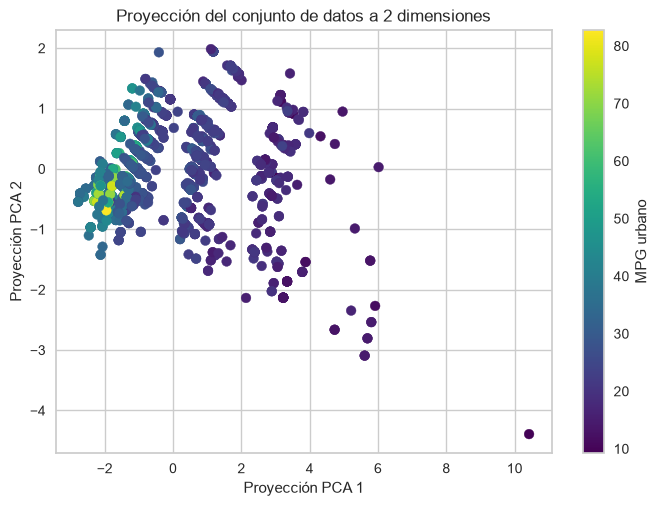

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada:", pca.explained_variance_ratio_.round(3))
print("Acumulada:", pca.explained_variance_ratio_.sum().round(3))
print(pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"]).round(2))

plt.scatter(X_pca[:, 0], X_pca[:, 1],c=df_procesado[mpg], cmap='viridis')
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.colorbar(label="MPG urbano")
plt.show()

Podemos observar como los vehiculos que mas MSG tienen estan concentrados a la izquieda del grafico, y vemos como ese MSG va disminuyendo a medida que nos desplazamos a la derecha de la variable de PCA 1.
Lo hice asi nomas, esto dijo claude:

PC1 (75,9%) es un índice de “tamaño del motor”. Las cuatro variables pesan con el mismo signo: cilindros (0,55), cilindrada (0,54), potencia (0,51) y peso (0,39, algo menos). Un valor alto de PC1 indica un auto con motor grande y potente, y uno bajo, un auto chico. Es el resultado esperado: confirma que peso, potencia, cilindrada y cilindros miden en gran parte lo mismo, y justifica por qué en la regresión sus coeficientes individuales van a ser inestables.

PC2 (16,1%) separa el peso del motor. Casi todo el peso de PC2 viene del peso del vehículo (0,92), con signo contrario al de potencia, cilindrada y cilindros (entre −0,18 y −0,29). Un valor alto de PC2 es un auto pesado para el tamaño de su motor (por ejemplo, un SUV con motor chico), y un valor bajo, un auto liviano con motor grande (típico de un deportivo). Es mi lectura de las cargas; no la verifiqué mirando qué autos caen en cada zona.

El signo de las cargas es arbitrario: el algoritmo podría devolver los componentes con el signo invertido. Lo que importa es cómo se comparan entre sí, y no si son positivas o negativas.

Lo que muestra el gráfico coloreado por MPG
El MPG baja de forma clara de izquierda a derecha. Los puntos amarillos y verdes (MPG de 50 a 80) están en la zona de PC1 bajo (motores chicos), y los violetas (MPG de 10 a 20) en PC1 alto. Es la evidencia visual más fuerte a favor de tu hipótesis: el tamaño del motor, resumido en un solo eje, se asocia con el consumo.
PC2 parece separar menos el color. A igual PC1, el MPG cambia poco entre arriba y abajo, aunque esto es una impresión visual y no una medición.
La caída del MPG no parece lineal. Cambia rápido en los primeros valores de PC1 y se aplana después. Esto respalda el uso de log(mpg) en la regresión.
Los puntos amarillos del extremo izquierdo son muy probablemente los híbridos, que ya vimos que dominan los MPG más altos. Es coherente con incluir la variable hibrido en el modelo.
Hay un punto muy aislado abajo a la derecha (PC1 ≈ 10, PC2 ≈ −4,5), con motor muy grande y liviano para su potencia. Podría ser el motor de 16 cilindros que vimos antes, pero no lo sé. Revisalo antes de decidir si lo dejás.
Dos cosas a tener en cuenta
Colorear por MPG no es circular, porque el MPG no se usó para calcular las componentes. Por eso sí se puede decir que el gráfico muestra una asociación. Pero es una visualización y no un test: la prueba de la hipótesis sigue siendo la regresión con el F global.
Las columnas verticales de puntos (por ejemplo, alrededor de PC1 = 1) vienen de que el peso va en clases de 250 lb y los cilindros toman pocos valores. No es un problema, pero conviene mencionarlo.

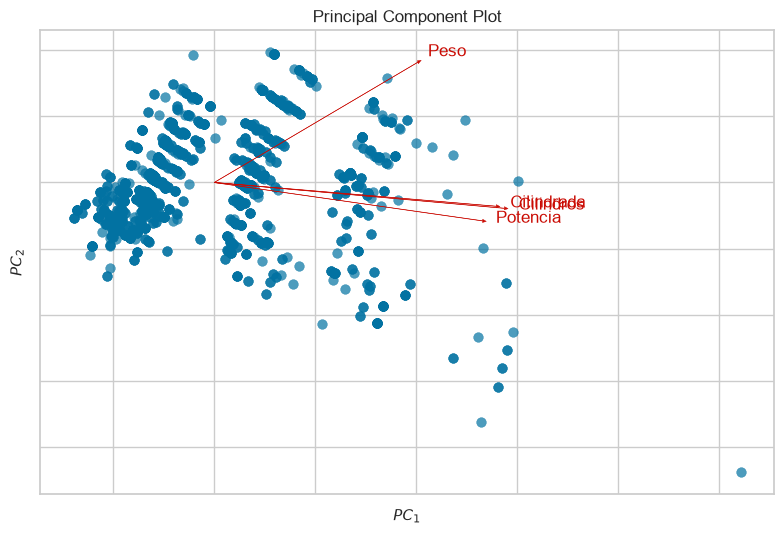

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [ ]:
from yellowbrick.features import PCA as PcaViz

# declaramos un objeto de la clase PcaViz:
viz = PcaViz(
      scale=True,          # le vamos a pedir que estandarice
        proj_features=True,  # le pedimos que dibuje las proyecciones de las features originales
        projection=2,        # le pedimos dos proyecciones
        features=["Peso", "Potencia", "Cilindrada", "Cilindros"],  # nombres cortos para las flechas
        colormap="viridis",  # misma escala de color que tu gráfico anterior
        alpha=0.7,      # le pedimos dos proyecciones
)
# lo aplicamos sobre los datos originales
viz.fit_transform(X)
# y pedimos que se grafique
viz.show()

“El biplot muestra que potencia, cilindrada y número de cilindros apuntan en una dirección prácticamente idéntica, lo que indica una correlación muy alta entre ellas y confirma que miden en gran medida el mismo atributo (el tamaño del motor). El peso forma un ángulo mayor con ese grupo, por lo que aporta información en parte independiente, que se refleja en la segunda componente.”

Potencia, cilindrada y cilindros apuntan casi en la misma dirección (hacia la derecha y apenas hacia abajo), tanto que se superponen. Cuando el ángulo entre dos flechas es muy chico, las variables están muy correlacionadas. Esto visualiza la colinealidad que anticipamos para la regresión: miden en gran parte lo mismo.
El peso sale en otra dirección, hacia arriba y a la derecha. Forma un ángulo bastante abierto con las otras tres, así que se asocia con ellas de forma positiva pero menos estrecha. Es la pista visual de que aporta algo de información propia, que es lo que captura PC2.
El largo de las flechas es parecido en las cuatro variables, o sea que todas están bien representadas en estos dos ejes. Es esperable con 92,1% de varianza explicada.

Todo esto coincide con las cargas que obtuviste: PC1 con las cuatro variables positivas y parecidas, y PC2 dominado por el peso (0,92), con signo contrario al de las otras tres.

Lo que muestran los puntos
De izquierda a derecha aumenta el tamaño del motor. El grupo grande a la izquierda son los autos de motor chico, y los puntos que se estiran hacia la derecha son motores más grandes y potentes.
Hay un punto muy aislado abajo a la derecha. Es el mismo valor extremo que vimos en el gráfico anterior, y conviene revisar qué auto es antes de decidir si lo dejás.
Las columnas de puntos se deben a que el peso va en clases de 250 lb y los cilindros toman pocos valores. Además, cada punto es un ensayo y no una configuración, así que varios puntos pueden ser el mismo auto repetido.

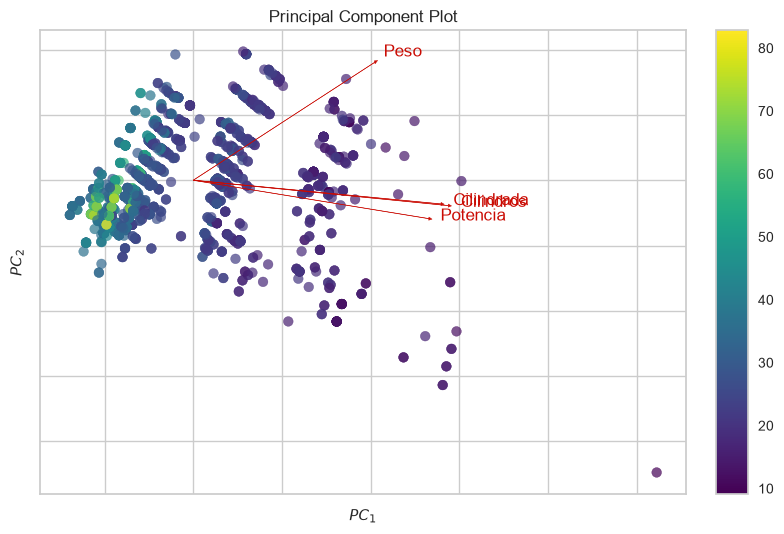

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [ ]:
# MPG de cada fila de X (yellowbrick no acepta valores faltantes en y)
y = df_procesado.loc[X.index, "RND_ADJ_FE"]
ok = y.notna()

# declaramos un objeto de la clase PcaViz:
viz = PcaViz(
    scale=True,          # le vamos a pedir que estandarice
    proj_features=True,  # le pedimos que dibuje las proyecciones de las features originales
    projection=2,        # le pedimos dos proyecciones
    features=["Peso", "Potencia", "Cilindrada", "Cilindros"],  # nombres cortos para las flechas
    colormap="viridis",  # misma escala de color que tu gráfico anterior
    alpha=0.7,
)
# lo aplicamos sobre los datos originales, pasando el MPG para colorear
viz.fit_transform(X[ok], y[ok])

# y pedimos que se grafique
viz.show()

Al ser cilindros y cilindrada tan parecidas, no es mejor quedarse con una o se pierde informacion.
Medimos las correlaciones 

In [ ]:
c1 = "Test Veh Displacement (L)"
c2 = "# of Cylinders and Rotors"

print("Pearson: ", round(X[c1].corr(X[c2]), 3))
print("Spearman:", round(X[c1].corr(X[c2], method="spearman"), 3))

Pearson:  0.921
Spearman: 0.907


veo que sale son los numeros de los cilindros 

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
X = df_procesado[["Equivalent Test Weight (lbs.)",
                  "Rated Horsepower",
                  "Test Veh Displacement (L)"]]
# estandarizamos X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(np.mean(X_scaled, axis=0))
print(np.std(X_scaled, axis=0))

[-4.88440532e-16 -7.37268727e-17  0.00000000e+00]
[1. 1. 1.]


Varianza explicada: [0.717 0.204]
Acumulada: 0.921
                                PC1   PC2
Equivalent Test Weight (lbs.)  0.50  0.86
Rated Horsepower               0.60 -0.43
Test Veh Displacement (L)      0.62 -0.28


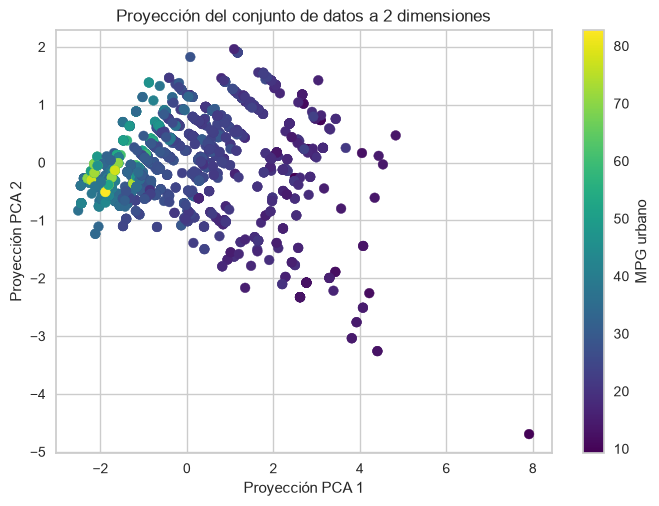

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada:", pca.explained_variance_ratio_.round(3))
print("Acumulada:", pca.explained_variance_ratio_.sum().round(3))
print(pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"]).round(2))

plt.scatter(X_pca[:, 0], X_pca[:, 1],c=df_procesado[mpg], cmap='viridis')
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.colorbar(label="MPG urbano")
plt.show()

Quitar los cilindros no cambia la conclusión del PCA, y el resultado queda más limpio.

Qué cambió respecto del PCA anterior
	        Con 4 variables	    Sin cilindros
PC1	        75,9%	            71,7%
PC2	        16,1%	            20,4%
Acumulada	92,1%	            92,1%

“Tras excluir el número de cilindros por su alta correlación con la cilindrada (r = 0,92), el PCA sobre peso, potencia y cilindrada estandarizados mostró que dos componentes explican el 92,1% de la varianza. La primera (71,7%), con cargas positivas y similares, se interpreta como un índice de tamaño y potencia; la segunda (20,4%) contrasta el peso del vehículo con el tamaño de su motor. Al colorear las configuraciones por MPG urbano, el consumo disminuye de forma sistemática a lo largo de la primera componente.”

Investigo el punto que me esta molestando al extremo izquierdo abajo

In [ ]:
cols = ["Represented Test Veh Make", "Represented Test Veh Model",
        "Equivalent Test Weight (lbs.)", "Rated Horsepower",
        "Test Veh Displacement (L)", "RND_ADJ_FE",
        "Test Fuel Type Description", "Test Procedure Description"]

cand = (X_pca[:, 0] > 7) & (X_pca[:, 1] < -4)    # la zona del punto aislado
print(cand.sum(), "punto(s) en esa zona")
print(df_procesado.loc[X.index[cand], cols])

1 punto(s) en esa zona
     Represented Test Veh Make Represented Test Veh Model  \
4116                   BUGATTI          Bugatti Pur Sport   

      Equivalent Test Weight (lbs.)  Rated Horsepower  \
4116                           4750              1500   

      Test Veh Displacement (L)  RND_ADJ_FE Test Fuel Type Description  \
4116                      7.993         9.5       Tier 2 Cert Gasoline   

                   Test Procedure Description  
4116  Federal fuel 2-day exhaust (w/can load)  


Un Bugatti Pur Sport: 1.500 hp, 7,993 L de cilindrada, 4.750 lb y 9,5 MPG urbanos, con gasolina de certificación. Es un hiperdeportivo, y el consumo de 9,5 MPG es coherente con ese motor.
Es un hiperdeportivo, no sabia ni que existian

<img src="https://cdn.motor1.com/images/mgl/qnAnv/s1/4x3/2021-bugatti-chiron-pur-sport-front-quarter-action.webp" width="500">


Ahora voy a empezar con la regresion, entonces veo la correlacion de las variables

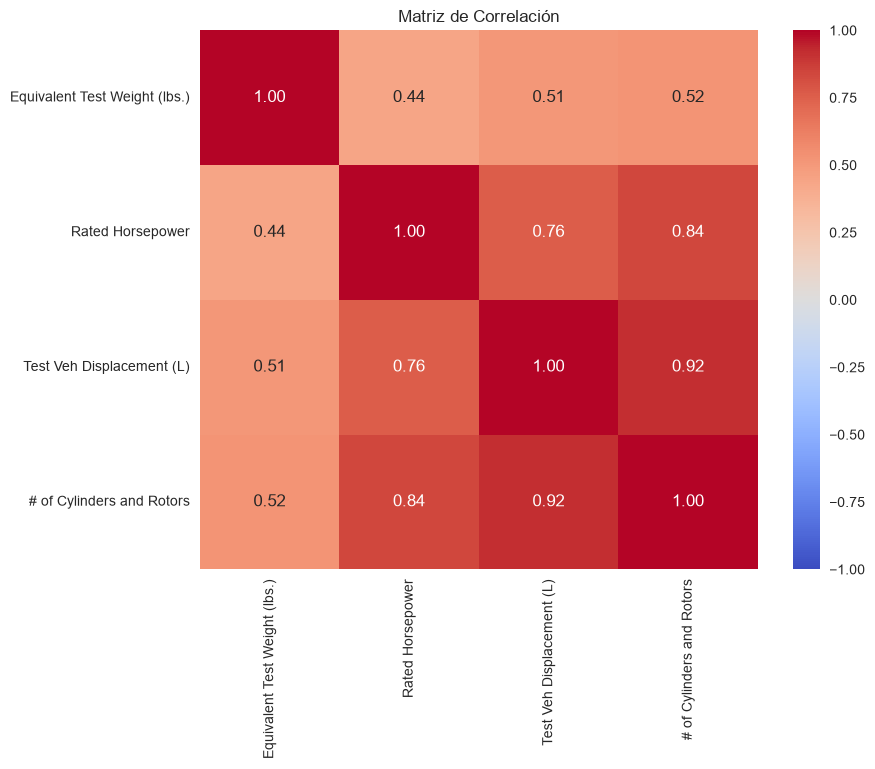

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
cols = ["Equivalent Test Weight (lbs.)",
                  "Rated Horsepower",
                  "Test Veh Displacement (L)",
                  "# of Cylinders and Rotors"]

# calculamos la matriz de correlación
correlation_matrix = df_procesado[cols].corr()
# la graficamos con un mapa de calor
plt.figure(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlación')
plt.show()

Se puede observar como todas las variables tienen una relacion positiva, las que estan mas fuertemente relacionadas, con un coeficiente de 0.92, son las de la cilindrada y el numero de cilindros, que tiene sentido porque tienen nombre parecido qsy.
Luego siguen la potencia con el numero de cilindros (0.84) y por ultimo de los que tienen significancia la cilindrada con la potencia(0.76).
Por lo cual se podrian decir que la potencia, el numero de cilindros y la cilindrada estan relacionados entre si.(eso no seria una hipotesis)

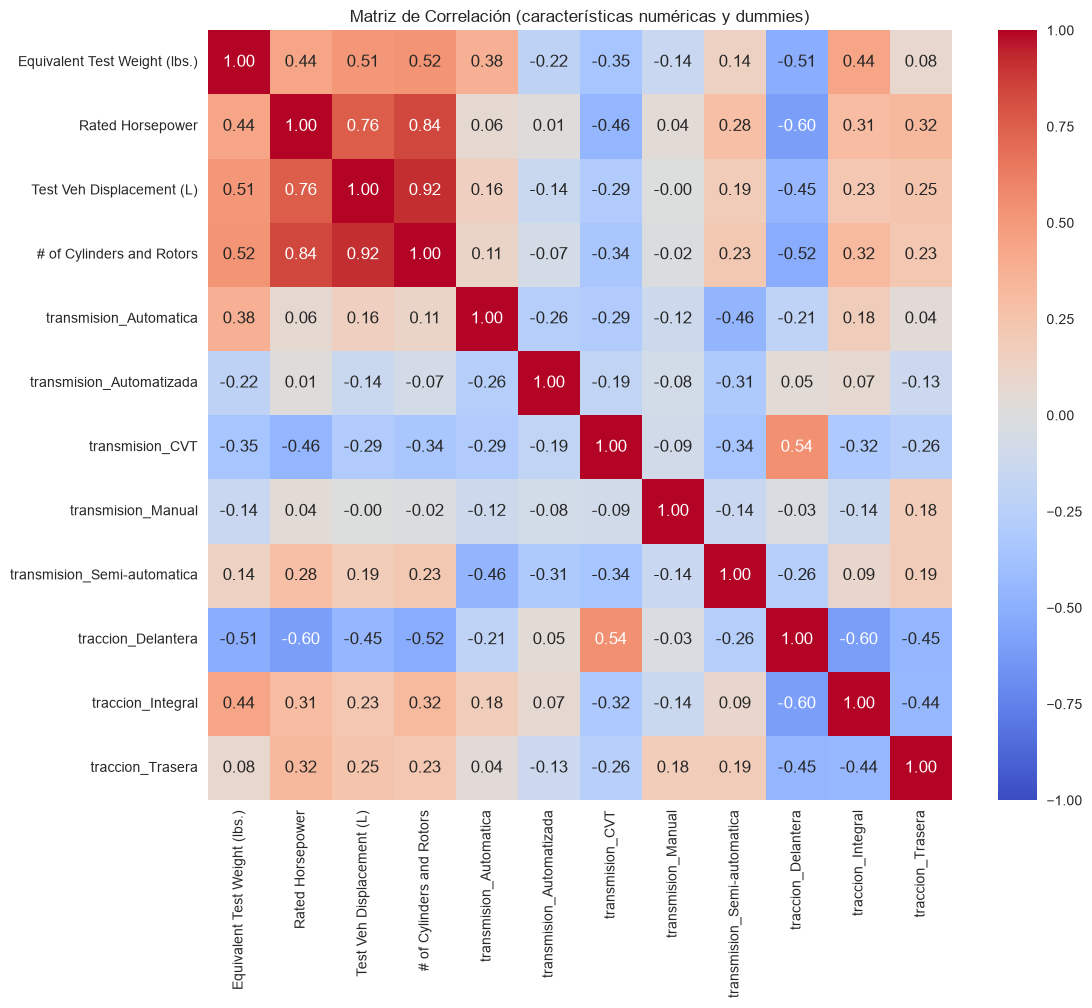

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

num = ["Equivalent Test Weight (lbs.)",
                  "Rated Horsepower",
                  "Test Veh Displacement (L)",
                  "# of Cylinders and Rotors"]
dums = [c for c in df_procesado.columns if c.startswith(("transmision_", "traccion_"))]

datos = df_procesado[num + dums].astype(float)

# calculamos la matriz de correlación
correlation_matrix = datos.corr()
# la graficamos con un mapa de calor
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlación (características numéricas y dummies)')
plt.show()

hay que ignorar dummy con dummy de la misma porque no es posible que esten las dos en el mismo vehiculo.

Las unicas que se ven mayormente relacionadas son las que ya explique 
NO SE SI ESTO ESTA BIEN

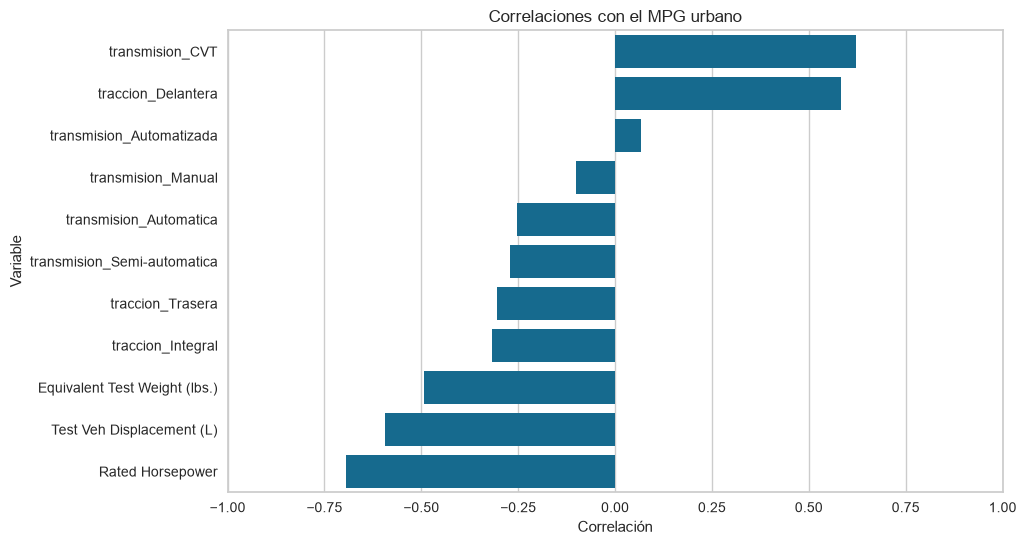

In [ ]:
mpg = "RND_ADJ_FE"
num = ["Equivalent Test Weight (lbs.)", "Rated Horsepower", "Test Veh Displacement (L)"]
dums = [c for c in df_procesado.columns if c.startswith(("transmision_", "traccion_"))]

# calculamos la matriz de correlación, ahora incluyendo el MPG
datos = df_procesado[num + dums + [mpg]].astype(float)
correlation_matrix = datos.corr()

# Selecciona solo las correlaciones con el MPG
mpg_correlations = correlation_matrix[mpg].drop(mpg)

# Ordena las correlaciones de mayor a menor
sorted_correlations = mpg_correlations.sort_values(ascending=False)

# Crea un gráfico de barras para visualizar las correlaciones
plt.figure(figsize=(10, 6))
plt.grid(True)
sns.barplot(x=sorted_correlations.values, y=sorted_correlations.index)
plt.title('Correlaciones con el MPG urbano')
plt.xlabel('Correlación')
plt.ylabel('Variable')
plt.xlim([-1, 1])
plt.show()

## T-SNE

Before t-SNE: (1542, 3)
After t-SNE: (1542, 2)


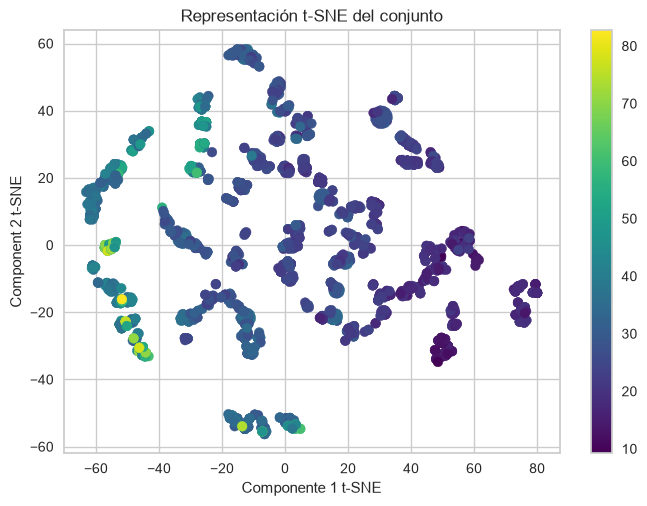

In [ ]:
from sklearn.manifold import TSNE

# creamos el objeto, lo fitteamos en nuestros datos y lo aplicamos sobre esos mismos
#X_tsne = TSNE(n_components=2).fit_transform(X_scaled) # sin random state
X_tsne = TSNE(n_components=2, random_state=10).fit_transform(X_scaled)  # con random state
# imprimimos los tamaños antes y después
print('Before t-SNE: {}'.format(X_scaled.shape))
print('After t-SNE: {}'.format(X_tsne.shape))

# graficamos los datos, el color de cada punto representa el valor de la casa
plt.scatter(X_tsne[:,0], X_tsne[:,1], c=df_procesado["RND_ADJ_FE"], cmap='viridis')
plt.grid(True)
plt.xlabel('Componente 1 t-SNE')
plt.ylabel('Component 2 t-SNE')
plt.title('Representación t-SNE del conjunto')
plt.colorbar()
plt.show()

## clustering

In [ ]:
print(X.corr().round(2))

                               Equivalent Test Weight (lbs.)  \
Equivalent Test Weight (lbs.)                           1.00   
Rated Horsepower                                        0.44   
Test Veh Displacement (L)                               0.51   

                               Rated Horsepower  Test Veh Displacement (L)  
Equivalent Test Weight (lbs.)              0.44                       0.51  
Rated Horsepower                           1.00                       0.76  
Test Veh Displacement (L)                  0.76                       1.00  


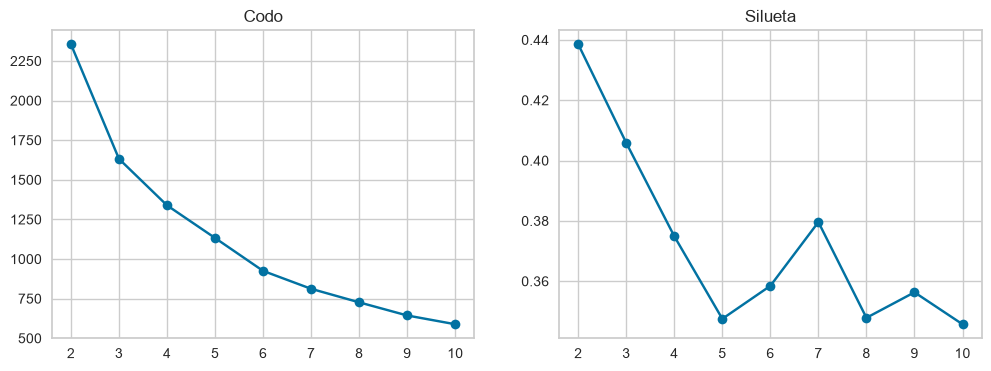

cluster
0    569
1    729
2    244
Name: count, dtype: int64
         Equivalent Test Weight (lbs.)  Rated Horsepower  \
cluster                                                    
0                              5153.78            341.86   
1                              3941.02            214.30   
2                              5225.41            546.02   

         Test Veh Displacement (L)  Axle Ratio  RND_ADJ_FE  
cluster                                                     
0                             2.97        3.47       25.26  
1                             2.08        3.76       35.70  
2                             4.89        3.56       17.35  


In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df_cl = df_procesado.reset_index(drop=True).copy()

# elegir k
ks = range(2, 11)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=10, n_init=10).fit(X_scaled)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X_scaled, km.labels_))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(ks, inercia, marker="o"); axs[0].set_title("Codo")
axs[1].plot(ks, silueta, marker="o"); axs[1].set_title("Silueta")
plt.show()

# modelo final
k = 3  # ajustalo según los gráficos
df_cl["cluster"] = KMeans(n_clusters=k, random_state=10, n_init=10).fit_predict(X_scaled)
print(df_cl["cluster"].value_counts().sort_index())

# perfil de cada cluster en unidades originales (incluye Axle Ratio y mpg para interpretar)
cols = list(X.columns) + ["Axle Ratio", mpg]
print(df_cl.groupby("cluster")[cols].mean().round(2))

In [ ]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations
from sklearn.cluster import KMeans

k = 3   # el k que elegiste
kmeans = KMeans(n_clusters=k, random_state=10, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

df_cl = df_procesado.reset_index(drop=True).copy()
df_cl["cluster"] = kmeans_labels
print(df_cl["cluster"].value_counts().sort_index())

col_mpg = "RND_ADJ_FE"
num_vars = ["Equivalent Test Weight (lbs.)", "Rated Horsepower",
            "Test Veh Displacement (L)", "# of Cylinders and Rotors"]

df_cl = df_procesado.reset_index(drop=True).copy()
df_cl["cluster"] = kmeans_labels   # las etiquetas del KMeans final (mismo orden que X_scaled)

# columnas dummy: ajustá el criterio a como las nombraste
dummies = [c for c in df_cl.columns if c.startswith(("transmision", "traccion")) and df_cl[c].dropna().isin([0, 1]).all()]
print(dummies)

cluster
0    569
1    729
2    244
Name: count, dtype: int64
['transmision_Automatica', 'transmision_Automatizada', 'transmision_CVT', 'transmision_Manual', 'transmision_Semi-automatica', 'traccion_Delantera', 'traccion_Integral', 'traccion_Trasera']


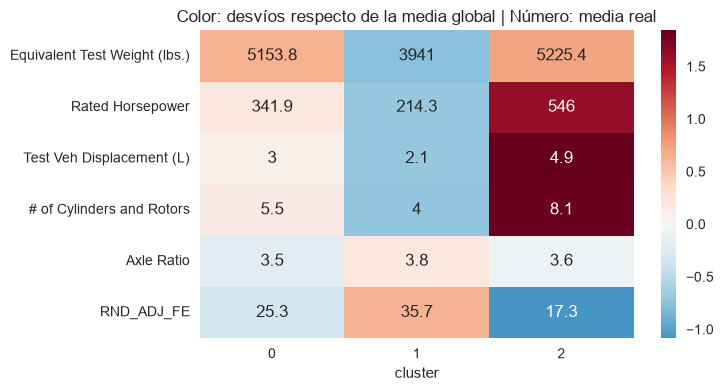

In [ ]:
col_mpg = "RND_ADJ_FE"
vars_perfil = num_vars + ["Axle Ratio", col_mpg]

trans_cols = [c for c in dummies if c.startswith("transmision_")]
drive_cols = [c for c in dummies if c.startswith("traccion_")]
df_cl["transmision"] = df_cl[trans_cols].astype(int).idxmax(axis=1).str.replace("transmision_", "")
df_cl["traccion"]    = df_cl[drive_cols].astype(int).idxmax(axis=1).str.replace("traccion_", "")

medias = df_cl.groupby("cluster")[vars_perfil].mean()
z = (medias - df_cl[vars_perfil].mean()) / df_cl[vars_perfil].std()

plt.figure(figsize=(7, 4))
sns.heatmap(z.T, annot=medias.T.round(1), fmt="g", cmap="RdBu_r", center=0)
plt.title("Color: desvíos respecto de la media global | Número: media real")
plt.show()

## Regresion lineal

Se puede hacer regresion lineal con las variables tan correlacionadas??

como esta en las filminas

In [ ]:
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
num = [
    "Equivalent Test Weight (lbs.)","Rated Horsepower","Test Veh Displacement (L)","# of Cylinders and Rotors"]

# Categorías de referencia (se dejan afuera para evitar multicolinealidad perfecta)
ref = ["transmision_Semi-automatica","traccion_Delantera"]

# Seleccionar las variables dummy, excluyendo las categorías de referencia
dums = [
    c for c in df_procesado.columns
    if c.startswith(("transmision_", "traccion_")) and c not in ref
]

# Unir variables numéricas y dummies
cols = num + dums

X = df_procesado[cols].copy()
y = df_procesado[mpg].copy()

# Conservar únicamente las filas donde mpg tiene un valor válido
mascara = y.notna() #es un true/false si han nan en mpg 

X = X.loc[mascara] #selecciona solo las filas que tienen true en mascara 
y = y.loc[mascara]

print("Observaciones eliminadas:", len(mascara) - mascara.sum())
print("Observaciones restantes:", len(y))

#Estandarizar variables numéricas
scaler = StandardScaler()

X_num_scaled = pd.DataFrame(
    scaler.fit_transform(X[num]),
    columns=num,
    index=X.index
)

 #Mantener las dummies sin estandarizar
X_dums = X[dums].copy()

#  Unir variables numéricas y dummies
X_scaled_df = pd.concat(
    [X_num_scaled, X_dums],
    axis=1
)

Observaciones eliminadas: 6
Observaciones restantes: 1536


In [ ]:
import statsmodels.api as sm
from statsmodels.stats.stattools import (
    durbin_watson,
    jarque_bera,
    omni_normtest
)
# Agregamos una constante como característica, para estimar la ordenada al origen
X_scaled_df_ = sm.add_constant(X_scaled_df)
# Ajustamos el modelo
model = sm.OLS(y, X_scaled_df_).fit()
# Imprimimos el resumen de los resultados
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.656
Model:                            OLS   Adj. R-squared:                  0.653
Method:                 Least Squares   F-statistic:                     290.3
Date:                Sat, 07 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:17:46   Log-Likelihood:                -4997.8
No. Observations:                1536   AIC:                         1.002e+04
Df Residuals:                    1525   BIC:                         1.008e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [ ]:
from statsmodels.stats.stattools import (
    durbin_watson,
    jarque_bera,
    omni_normtest
)

residuos = model.resid
omnibus, p_omnibus = omni_normtest(residuos)
dw = durbin_watson(residuos)
jb, p_jb, skew, kurtosis = jarque_bera(residuos)
cond = model.condition_number

print("Omnibus:", omnibus)
print("Prob(Omnibus):", p_omnibus)
print("Durbin-Watson:", dw)
print("Jarque-Bera:", jb)
print("Prob(JB):", p_jb)
print("Skew:", skew)
print("Kurtosis:", kurtosis)
print("Condition Number:", cond)

Omnibus: 565.2273459867333
Prob(Omnibus): 1.829958785291269e-123
Durbin-Watson: 1.1167673393460529
Jarque-Bera: 3034.805288661117
Prob(JB): 0.0
Skew: 1.6368918614159742
Kurtosis: 9.05814928599903
Condition Number: 10.56048239987382


Qué dice sobre tu hipótesis
F = 290,3 con p ≈ 0. Se rechaza H0: las características técnicas se asocian conjuntamente con el MPG urbano.
R² ajustado = 0,653. Explican alrededor del 65% de la variación del MPG. Con 1.536 observaciones el test F casi siempre sale significativo, así que el dato que le da peso a la conclusión es este R².

BONDAD DE AJUSTE

El modelo explica aproximadamente el 65,6 % de la variabilidad de RND_ADJ_FE mediante las variables predictoras seleccionadas.

El 34,4 % restante no es explicado por este modelo
Es un resultado razonable: el modelo tiene capacidad explicativa, aunque todavía hay variabilidad que no logra capturar.

Además, el R² ajustado (0.653) es muy cercano al R² (0.656). Esto indica que, al penalizar por la cantidad de variables predictoras, el poder explicativo del modelo cambia muy poco.

EVALUACION GLOBAL
- f-statistic = 290.3
- prob(f-statistic) = 0.0

Esto quiere decir que el modelo aporta informacion importante.

El test F evalúa las siguientes hipótesis estadísticas:
- H₀: todos los coeficientes de las variables predictoras son iguales a cero (no existe asociación lineal conjunta).
- H₁: al menos uno de los coeficientes es distinto de cero (existe asociación lineal conjunta).
Como el valor p del test F es extremadamente pequeño (menor que 0.001), rechazamos H₀.
**Evidencia a favor de la hipótesis**
Esto significa que existe evidencia estadística de que las características técnicas consideradas están asociadas conjuntamente con la eficiencia de combustible urbana.

COEFICIENTE Y SIGNIFICANCIA

ninguno de los p-valores es mayor a 0.05 por lo tanto todos aportan significancia al modelo. Sin embargo, transmision_Automatica tiene un p-valor de 0.047, por lo que su significancia es bastante más débil que la de las demás.

CRITERIOS DE DIAGNOSTICO





SUPUESTO DE NORMALIDAD EN LOS RESIDUOS
- la probabilidad de del test de obnibus es menor a 0.05, por lo que se rechaza la normalidad, pasa lo mismo con el test jaque vera

INDEPENDENCIA DE LOS RESIDUOS
test durbin-watson : 1.1167673393460529, no esta en el rango [1.5-2.5] que indica independencia, entonces hay dependencia entre los residuos

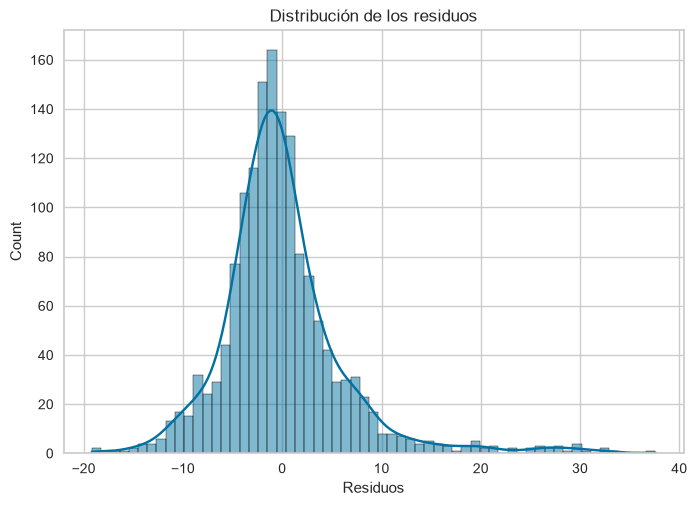

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(model.resid, kde=True)
plt.title("Distribución de los residuos")
plt.xlabel("Residuos")
plt.show()

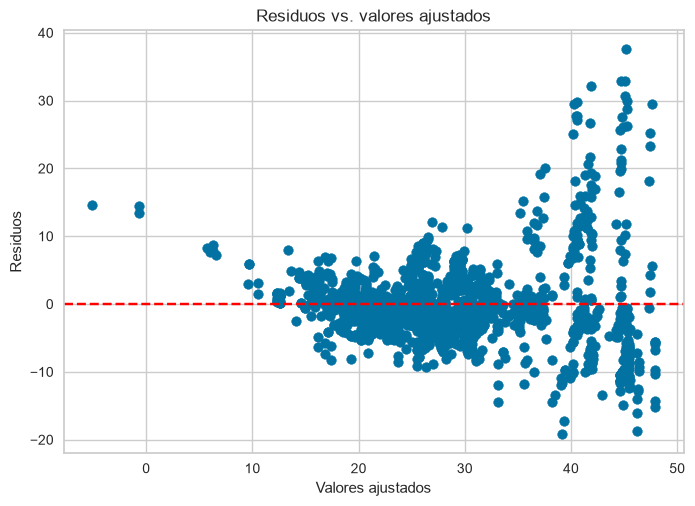

In [ ]:
plt.scatter(model.fittedvalues, model.resid)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Residuos vs. valores ajustados")
plt.show()

Esto sugiere heterocedasticidad, es decir, que la varianza de los errores no es constante.
tambien se ve que no hay linealidad 

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp = het_breuschpagan(model.resid, model.model.exog)

print("LM Statistic:", bp[0])
print("Prob(LM):", bp[1])
print("F Statistic:", bp[2])
print("Prob(F):", bp[3])

LM Statistic: 266.4190847434941
Prob(LM): 1.900637277350569e-51
F Statistic: 32.00182826879862
Prob(F): 1.0959244084146923e-56


Efectivamente no hay homocedasticidad en los errores 

vemos entonces que no se cumplen entoces ni los supuestos de normalidad, de independencia, de homocedasticidad y creo que linealidad tampo (NO SIRVE??)

Hay un detalle que no ignoraría: los coeficientes de potencia y cilindrada son negativos, mientras que el de cilindros es positivo.

Esto no necesariamente está mal, pero puede estar relacionado con la multicolinealidad.

Por ejemplo, la potencia, la cilindrada y la cantidad de cilindros pueden estar relacionadas entre sí. Cuando incorporamos todas estas variables simultáneamente, los coeficientes representan sus efectos parciales, no sus relaciones individuales con el consumo.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame()

vif["Variable"] = X_scaled_df_.columns

vif["VIF"] = [
    variance_inflation_factor(X_scaled_df_.values, i)
    for i in range(X_scaled_df_.shape[1])
]

print(vif)

                         Variable       VIF
0                           const  1.000000
1   Equivalent Test Weight (lbs.)  1.980268
2                Rated Horsepower  4.159894
3       Test Veh Displacement (L)  7.149279
4       # of Cylinders and Rotors  9.936895
5          transmision_Automatica  1.423075
6        transmision_Automatizada  1.360584
7                 transmision_CVT  1.868710
8              transmision_Manual  1.119305
9               traccion_Integral  2.340485
10               traccion_Trasera  2.076218


es alto en numero de cilindros y cilindrada. voy a hacer un modelo sin el numero de variables y comparar:

In [ ]:
# Eliminar cantidad de cilindros y rotores
X_reducido = X_scaled_df.drop(
    columns=["# of Cylinders and Rotors"]
)

# Agregar constante
X_reducido = sm.add_constant(X_reducido)

# Ajustar modelo
model_reducido = sm.OLS(y, X_reducido).fit()

print(model_reducido.summary())

                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.645
Model:                            OLS   Adj. R-squared:                  0.643
Method:                 Least Squares   F-statistic:                     308.4
Date:                Sat, 07 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:17:47   Log-Likelihood:                -5020.7
No. Observations:                1536   AIC:                         1.006e+04
Df Residuals:                    1526   BIC:                         1.011e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

para comparar ver AIC Y BIC (mientras mas pequeños mejor):

             Modelo completo  Modelo reducido
R²                  0.655636         0.645230
R² ajustado         0.653377         0.643137
AIC             10017.692347     10061.418717
BIC             10076.398653     10114.788086

Con estos resultados, conviene conservar el modelo completo, incluyendo # of Cylinders and Rotors, aunque presente multicolinealidad.

Veamos por qué:
- R²: el modelo completo explica el 65,56 % de la variabilidad, mientras que el reducido explica el 64,52 %.
- R² ajustado: también favorece al modelo completo, incluso penalizando la cantidad de variables.
- AIC y BIC: ambos son menores en el modelo completo. Esto indica que ofrece un mejor equilibrio entre ajuste y complejidad.

Por ahora nos quedamos con el completo

## AHORA LO VOY A HACER POR VEHICULO, NO ENTRADA DE TEST URBANO    

In [ ]:
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
num = [
    "Equivalent Test Weight (lbs.)","Rated Horsepower","Test Veh Displacement (L)","# of Cylinders and Rotors"]

# Categorías de referencia (se dejan afuera para evitar multicolinealidad perfecta)
ref = ["transmision_Semi-automatica","traccion_Delantera"]

# Seleccionar las variables dummy, excluyendo las categorías de referencia
dums = [
    c for c in df_procesado.columns
    if c.startswith(("transmision_", "traccion_")) and c not in ref
]

# Unir variables numéricas y dummies
cols = num + dums

X = df_procesado[cols].copy()
y = df_procesado[mpg].copy()

# Conservar únicamente las filas donde mpg tiene un valor válido
mascara = y.notna() #es un true/false si han nan en mpg 

X = X.loc[mascara] #selecciona solo las filas que tienen true en mascara 
y = y.loc[mascara]

print("Observaciones eliminadas:", len(mascara) - mascara.sum())
print("Observaciones restantes:", len(y))

#Estandarizar variables numéricas
scaler = StandardScaler()

X_num_scaled = pd.DataFrame(
    scaler.fit_transform(X[num]),
    columns=num,
    index=X.index
)

 #Mantener las dummies sin estandarizar
X_dums = X[dums].copy()

#  Unir variables numéricas y dummies
X_scaled_df = pd.concat(
    [X_num_scaled, X_dums],
    axis=1
)

Observaciones eliminadas: 6
Observaciones restantes: 1536


In [ ]:
import statsmodels.api as sm
from statsmodels.stats.stattools import (
    durbin_watson,
    jarque_bera,
    omni_normtest
)
# Agregamos una constante como característica, para estimar la ordenada al origen
X_scaled_df_ = sm.add_constant(X_scaled_df)
# Ajustamos el modelo
model = sm.OLS(y, X_scaled_df_).fit()
# Imprimimos el resumen de los resultados
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.656
Model:                            OLS   Adj. R-squared:                  0.653
Method:                 Least Squares   F-statistic:                     290.3
Date:                Sat, 07 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:17:47   Log-Likelihood:                -4997.8
No. Observations:                1536   AIC:                         1.002e+04
Df Residuals:                    1525   BIC:                         1.008e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [ ]:
residuos = model.resid
omnibus, p_omnibus = omni_normtest(residuos)
dw = durbin_watson(residuos)
jb, p_jb, skew, kurtosis = jarque_bera(residuos)
cond = model.condition_number

print("Omnibus:", omnibus)
print("Prob(Omnibus):", p_omnibus)
print("Durbin-Watson:", dw)
print("Jarque-Bera:", jb)
print("Prob(JB):", p_jb)
print("Skew:", skew)
print("Kurtosis:", kurtosis)
print("Condition Number:", cond)

Omnibus: 565.2273459867333
Prob(Omnibus): 1.829958785291269e-123
Durbin-Watson: 1.1167673393460529
Jarque-Bera: 3034.805288661117
Prob(JB): 0.0
Skew: 1.6368918614159742
Kurtosis: 9.05814928599903
Condition Number: 10.56048239987382


SUPUESTO DE NORMALIDAD EN LOS RESIDUOS
- la probabilidad de del test de obnibus es menor a 0.05, por lo que se rechaza la normalidad, pasa lo mismo con el test jaque vera

INDEPENDENCIA DE LOS RESIDUOS
test durbin-watson : 1.1167673393460529, no esta en el rango [1.5-2.5] que indica independencia, entonces hay dependencia entre los residuos

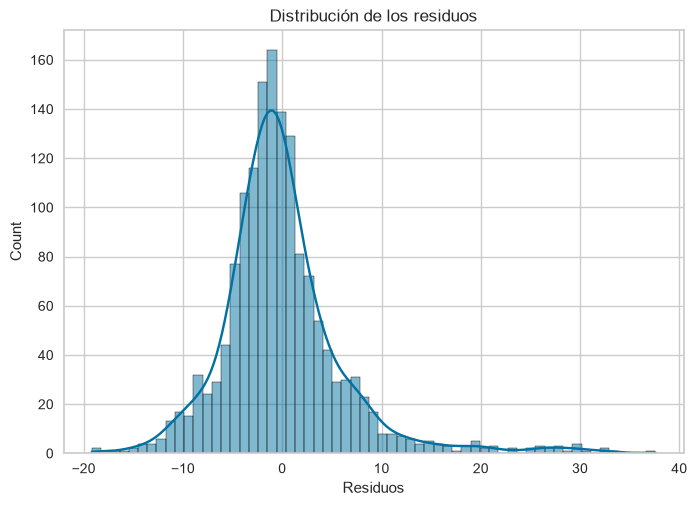

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(model.resid, kde=True)
plt.title("Distribución de los residuos")
plt.xlabel("Residuos")
plt.show()

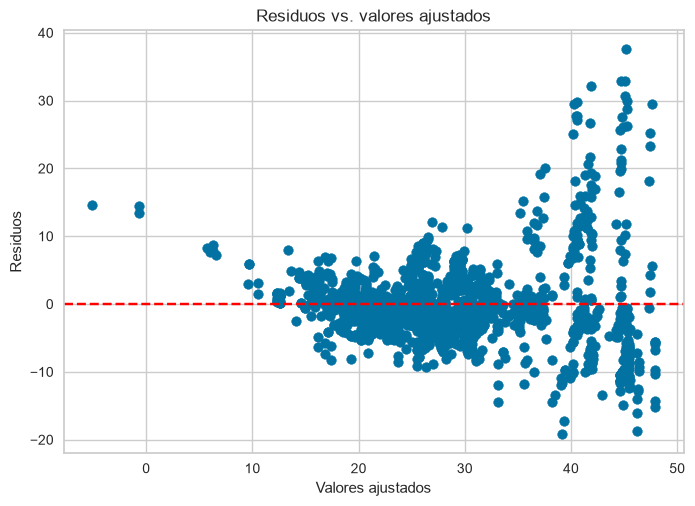

In [ ]:
plt.scatter(model.fittedvalues, model.resid)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Residuos vs. valores ajustados")
plt.show()

Indicador	    Con repeticiones	Sin repeticiones
Observaciones	1536	            1079
R²	            0,656	            0,674
R² ajustado	    0,653	            0,671
Estadístico F	290,3	            220,8
AIC	            10017,7	            6713
BIC	            10076,4	            6768

El modelo sin repeticiones presenta un R² mayor: explica aproximadamente el 67,4 % de la variabilidad de la eficiencia, frente al 65,6 % del anterior.

Importante: no compares directamente los AIC y BIC de ambos modelos para decidir cuál es mejor, porque se estimaron con distintas cantidades de observaciones. Además, eliminar duplicados cambia la población de análisis.
2. Interpretación de los coeficientes
Como las variables numéricas están estandarizadas, sus coeficientes representan el cambio esperado en RND_ADJ_FE ante un aumento de una desviación estándar del predictor, manteniendo los demás constantes.

Lo vi medio por arriba pero creo que pasa lo mismo con los supuestos de los residuos y tambien apoya la hipotesis

##hago pca dejando solo un auto

[ 7.88032609e-17  1.18204891e-16 -5.25355073e-17]
[1. 1. 1.]
Varianza explicada: [0.733 0.188]
Acumulada: 0.921
                                PC1   PC2
Equivalent Test Weight (lbs.)  0.52  0.85
Rated Horsepower               0.60 -0.42
Test Veh Displacement (L)      0.61 -0.31


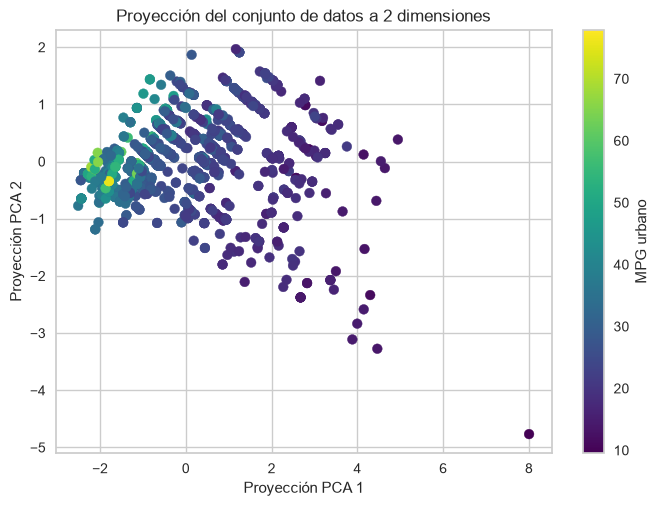

In [ ]:
CLAVE = ["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"]
# quedar primera fila de cada columna
df_procesado = df_procesado.drop_duplicates(subset=CLAVE, keep="first").reset_index(drop=True)
X = df_procesado[["Equivalent Test Weight (lbs.)",
                  "Rated Horsepower",
                  "Test Veh Displacement (L)"]]
# estandarizamos X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(np.mean(X_scaled, axis=0))
print(np.std(X_scaled, axis=0))

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada:", pca.explained_variance_ratio_.round(3))
print("Acumulada:", pca.explained_variance_ratio_.sum().round(3))
print(pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"]).round(2))

plt.scatter(X_pca[:, 0], X_pca[:, 1],c=df_procesado[mpg], cmap='viridis')
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.colorbar(label="MPG urbano")
plt.show()